# Concept Bottleneck Model vs direct model on SkinCon: reproducing the report

This notebook reproduces every number and figure of the report, section by section:

| Report | Notebook section |
|---|---|
| S2 Data | 2 |
| S3 Method (models, losses, training, protocol), Figure 1 | 3, 4 |
| S4 Table 1 | 5 |
| S5.1 Concept probing, Figure 2 | 6 |
| S5.2 SHAP, Figures 3 and 4; Grad-CAM, Figures 5 and 6 | 7, 8 |
| S6 Q2 outside share, Figure 7 | 9 |

**Files needed** (next to this notebook):

* `fitzpatrick17k_concepts.csv`: SkinCon concept annotations
* `fitzpatrick17k_vit_large_patch16_dinov3_lvd1689m_cls_float32.npy`: DINOv3 CLS features, one row per row of `fitzpatrick17k.csv`. If it is missing, section 1 computes it from the images (about 15 min on a GPU).

The Fitzpatrick17k images and metadata (`fitzpatrick17k.csv`) are downloaded from Kaggle (`asosenge/fitzpatrick17k`) into `./data`, and the DINOv3 weights come from timm / Hugging Face. Both downloads happen automatically on the first run.
Sections 1–6 run in a few minutes. Sections 7–9 (Grad-CAM) need a GPU.

**Packages:** see `requirements.txt`.

## 0. Setup
All hyper-parameters of the Method section live in the cell below.

In [1]:
import copy
import os
import random
from pathlib import Path

import matplotlib.patches as mpatches
from matplotlib.colors import to_rgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image, ImageFile, ImageOps
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

import warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # harmless tqdm notice
ImageFile.LOAD_TRUNCATED_IMAGES = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---- files
DATA_DIR = Path(".")                       # folder with the concepts CSV and the features
CONCEPTS_FILE = DATA_DIR / "fitzpatrick17k_concepts.csv"
EMBEDDINGS_FILE = DATA_DIR / "fitzpatrick17k_vit_large_patch16_dinov3_lvd1689m_cls_float32.npy"
KAGGLE_CACHE = DATA_DIR / "data"           # where kagglehub stores the Fitzpatrick17k download
DINOV3 = "vit_large_patch16_dinov3.lvd1689m"
KAGGLE_DATASET = "asosenge/fitzpatrick17k"

# ---- data
TARGETS = ["nine_partition_label", "three_partition_label"]
MIN_CONCEPT_POSITIVES = 50                 # keep the 22 concepts with >= 50 positive images
MIN_SAMPLES_PER_CLASS = 5
FLAG_COLUMN = "Do not consider this image" # images the annotators flagged as unusable

# ---- training (Method section)
SEED = 42
N_FOLDS = 5
VAL_FRACTION = 0.15                        # of each training fold, for early stopping only
HIDDEN_DIM = 128
DROPOUT = 0.10
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 100
PATIENCE = 8

# ---- Grad-CAM (sections 7-9)
GRADCAM_BLOCK = -4                         # block 21 of 24
TOP_FRACTION = 0.20                        # "important region" = top 20% of the patches
N_GRADCAM_IMAGES = 200
COLORS = {"direct": "#2a78d6", "cbm": "#eb6834", "dino": "#7d7d7d"}

print(f"device: {DEVICE}")
assert CONCEPTS_FILE.exists(), f"{CONCEPTS_FILE.name} must be next to the notebook"


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device: cuda


## 1. Fitzpatrick17k download and DINOv3 features

The Kaggle dataset contains the images and the metadata file `fitzpatrick17k.csv`. kagglehub caches the download, so this only takes time on the first run.
Every image is passed once through the frozen DINOv3 ViT-L/16 and its CLS token $\phi(x) \in \mathbb{R}^{1024}$ is stored.
The helpers below are also used for Grad-CAM later. The extraction itself is skipped when the `.npy` file already exists.

In [2]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}


os.environ.setdefault("KAGGLEHUB_CACHE", str(KAGGLE_CACHE))
import kagglehub

KAGGLE_ROOT = Path(kagglehub.dataset_download(KAGGLE_DATASET))
METADATA_FILE = min(KAGGLE_ROOT.rglob("fitzpatrick17k.csv"), key=lambda p: len(p.parts))
print(f"metadata: {METADATA_FILE.relative_to(KAGGLE_ROOT)} (in the Kaggle download)")


def index_images(metadata, root=KAGGLE_ROOT):
    # Map md5hash -> image path inside the Kaggle download.
    by_name = {}
    for p in root.rglob("*"):
        if p.suffix.lower() in IMAGE_EXTENSIONS:
            by_name.setdefault(p.name, p)
    paths = {}
    for row in metadata.itertuples(index=False):
        for name in [Path(str(row.url_alphanum)).name, row.md5hash, *(row.md5hash + e for e in sorted(IMAGE_EXTENSIONS))]:
            if name in by_name:
                paths[row.md5hash] = by_name[name]
                break
    return paths


def load_image(path):
    with Image.open(path) as image:
        return ImageOps.exif_transpose(image).convert("RGB")


def load_dinov3():
    # Frozen DINOv3 and its own preprocessing (resize + centre crop to 256 x 256, normalise).
    import timm
    model = timm.create_model(DINOV3, pretrained=True, num_classes=0).eval().to(DEVICE)
    for p in model.parameters():
        p.requires_grad_(False)
    transform = timm.data.create_transform(**timm.data.resolve_model_data_config(model), is_training=False)
    return model, transform


embeddings_path = EMBEDDINGS_FILE
if not embeddings_path.exists():
    metadata = pd.read_csv(METADATA_FILE)
    paths = index_images(metadata)
    assert len(paths) == len(metadata), "every CSV row needs an image"
    model, transform = load_dinov3()
    rows = []
    for start in range(0, len(metadata), 64):
        batch = torch.stack([transform(load_image(paths[m])) for m in metadata.md5hash[start:start + 64]])
        with torch.no_grad(), torch.autocast(DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            rows.append(model.forward_features(batch.to(DEVICE))[:, 0].float().cpu().numpy())   # CLS token
    np.save(embeddings_path, np.concatenate(rows))
    del model
print("features:", np.load(embeddings_path, mmap_mode="r").shape)

metadata: fitzpatrick17k.csv (in the Kaggle download)
features: (16577, 1024)


## 2. Data

SkinCon rows are matched to Fitzpatrick17k (and thereby to the feature matrix) through `ImageID → md5hash`.
We drop flagged images, keep the $J = 22$ concepts with at least 50 positives, and drop classes with fewer than 5 images.

In [3]:
def load_data(target):
    metadata = pd.read_csv(METADATA_FILE).assign(embedding_row=lambda d: np.arange(len(d)))
    embeddings = np.load(EMBEDDINGS_FILE, mmap_mode="r")
    concepts = pd.read_csv(CONCEPTS_FILE)
    concepts["md5hash"] = concepts["ImageID"].astype(str).str.replace(r"\.[^.]+$", "", regex=True)

    df = concepts.merge(metadata, on="md5hash", how="inner", validate="one_to_one")
    df = df[df[FLAG_COLUMN].fillna(0).astype(int) == 0].reset_index(drop=True)

    # Concepts: all annotation columns with at least 50 positive images, most frequent first.
    candidates = [c for c in concepts.columns if c not in {"ImageID", "md5hash", FLAG_COLUMN} and not c.startswith("Unnamed:")]
    positives = df[candidates].sum()
    concept_names = positives[positives >= MIN_CONCEPT_POSITIVES].sort_values(ascending=False).index.tolist()

    # Classes too rare to stratify over 5 folds are dropped.
    labels = df[target].astype(str)
    counts = labels.value_counts()
    df = df[df[target].notna() & labels.isin(counts[counts >= MIN_SAMPLES_PER_CLASS].index)].reset_index(drop=True)

    encoder = LabelEncoder().fit(df[target].astype(str))
    return {"X": np.asarray(embeddings[df.embedding_row.to_numpy()], dtype=np.float32),   # phi(x), N x 1024
            "C": df[concept_names].to_numpy(np.float32),                                   # c, N x 22
            "y": encoder.transform(df[target].astype(str)).astype(np.int64),                                # diagnosis
            "classes": encoder.classes_.tolist(), "concept_names": concept_names,
            "md5hash": df.md5hash.to_numpy()}


data = {t: load_data(t) for t in TARGETS}
d = data["nine_partition_label"]
print(f"N = {len(d['y'])} images, J = {len(d['concept_names'])} concepts")
for t in TARGETS:
    counts = pd.Series(data[t]["y"]).map(dict(enumerate(data[t]["classes"]))).value_counts()
    print(f"\n{t} (K = {len(counts)}):\n" + counts.to_string())

N = 3230 images, J = 22 concepts

nine_partition_label (K = 9):
inflammatory                    2102
malignant epidermal              301
genodermatoses                   218
benign epidermal                 202
benign dermal                    180
malignant melanoma               108
benign melanocyte                 49
malignant cutaneous lymphoma      44
malignant dermal                  26

three_partition_label (K = 3):
non-neoplastic    2320
malignant          479
benign             431


## 3. Models

Both models start with the same kind of hidden layer $h(z) = \mathrm{GELU}(Wz + b) \in \mathbb{R}^{128}$ (with dropout 0.1); each has its own weights.

* **Direct model:** $\hat p^{\,\mathrm{dir}} = \mathrm{softmax}(V\,h_\theta(z) + v)$
* **CBM:** concept part $\hat c = \sigma(U\,h_\psi(z) + u) \in [0,1]^{22}$, then classifier $\hat p^{\,\mathrm{cbm}} = \mathrm{softmax}(A\,\hat c + a)$. The diagnosis only sees the image through the 22 concept probabilities.

In [4]:
class DirectModel(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim, HIDDEN_DIM), nn.GELU(), nn.Dropout(DROPOUT))   # h_theta
        self.classifier = nn.Linear(HIDDEN_DIM, num_classes)                                              # V, v

    def forward(self, z):
        return self.classifier(self.encoder(z))


class ConceptBottleneck(nn.Module):
    def __init__(self, input_dim, num_concepts, num_classes):
        super().__init__()
        self.concept_part = nn.Sequential(                                            # h_psi, then U, u
            nn.Linear(input_dim, HIDDEN_DIM), nn.GELU(), nn.Dropout(DROPOUT),
            nn.Linear(HIDDEN_DIM, num_concepts))
        self.classifier = nn.Linear(num_concepts, num_classes)                        # A, a

    def forward(self, z):
        concept_logits = self.concept_part(z)
        return concept_logits, self.classifier(torch.sigmoid(concept_logits))

## 4. Training

* **Losses.** Diagnosis: class-weighted cross-entropy with $w_k = N_\mathrm{train} / (K N_k)$. Concepts: binary cross-entropy averaged over the 22 concepts.
* **Optimisation.** AdamW (lr $10^{-3}$, weight decay $10^{-4}$), batch size 128. Training stops when the validation score has not improved for 8 epochs, and the best epoch is kept.
* **Direct model.** Trained on the diagnosis loss; early stopping on macro-F1.
* **Sequential CBM.** Stage 1 trains the concept part on the concept loss only, with early stopping on mean concept AUROC. Stage 2 trains the classifier to predict the diagnosis.

In [5]:
def class_metrics(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0)}


def safe_auroc(labels, scores):
    # AUROC is undefined when a concept is all-present or all-absent in the evaluated images.
    return roc_auc_score(labels, scores) if 0 < labels.sum() < len(labels) else np.nan


def weighted_ce(y_train, num_classes):
    w = len(y_train) / (num_classes * np.maximum(np.bincount(y_train, minlength=num_classes), 1))
    return nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=DEVICE))


def make_loader(*arrays):
    return DataLoader(TensorDataset(*map(torch.from_numpy, arrays)), batch_size=BATCH_SIZE, shuffle=True)


@torch.inference_mode()
def run(module, z):
    # Forward pass on a numpy array, eval mode, returns numpy.
    module.eval()
    out = module(torch.from_numpy(z).to(DEVICE))
    return tuple(o.cpu().numpy() for o in out) if isinstance(out, tuple) else out.cpu().numpy()


def fit(model, loader, batch_loss, val_score, max_epochs=MAX_EPOCHS, patience=PATIENCE):
    # Generic loop: AdamW, early stopping on a validation score (higher = better), keeps the best epoch.
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    best_state, best, stale = None, -np.inf, 0
    for _ in range(max_epochs):
        model.train()
        for batch in loader:
            optimizer.zero_grad(set_to_none=True)
            batch_loss(*(t.to(DEVICE) for t in batch)).backward()
            optimizer.step()
        score = val_score()
        if score > best:
            best_state, best, stale = copy.deepcopy(model.state_dict()), score, 0
        else:
            stale += 1
            if stale >= patience:
                break
    model.load_state_dict(best_state)
    return model.eval()


def train_direct(Z, C, y, tr, va, K, seed):
    seed_everything(seed)
    model = DirectModel(Z.shape[1], K).to(DEVICE)
    ce = weighted_ce(y[tr], K)
    return fit(model, make_loader(Z[tr], C[tr], y[tr]),
               batch_loss=lambda zb, cb, yb: ce(model(zb), yb),
               val_score=lambda: f1_score(y[va], run(model, Z[va]).argmax(1), average="macro", zero_division=0))


def train_concept_part(Z, C, tr, va, seed):
    # Sequential CBM, stage 1: concept part on the concept loss only (never sees the diagnosis).
    seed_everything(seed)
    part = ConceptBottleneck(Z.shape[1], C.shape[1], 2).concept_part.to(DEVICE)
    bce = nn.BCEWithLogitsLoss()

    def mean_auroc():
        scores = run(part, Z[va])
        return np.nanmean([safe_auroc(C[va, j], scores[:, j]) for j in range(C.shape[1])])

    return fit(part, make_loader(Z[tr], C[tr], np.zeros(len(tr), dtype=np.int64)),
               batch_loss=lambda zb, cb, _: bce(part(zb), cb), val_score=mean_auroc)


def train_cbm(Z, C, y, tr, va, K, seed):
    # Sequential CBM, stage 2: diagnosis from the concept probabilities.
    seed_everything(seed)
    cbm = ConceptBottleneck(Z.shape[1], C.shape[1], K).to(DEVICE)
    ce, bce = weighted_ce(y[tr], K), nn.BCEWithLogitsLoss()

    def batch_loss(zb, cb, yb):
        concept_logits, class_logits = cbm(zb)
        return ce(class_logits, yb) + bce(concept_logits, cb)

    return fit(cbm, make_loader(Z[tr], C[tr], y[tr]), batch_loss,
               val_score=lambda: f1_score(y[va], run(cbm, Z[va])[1].argmax(1), average="macro", zero_division=0))


def concept_probes(h_train, h_test, c_train, c_test):
    # One L2-regularised logistic probe per concept on a representation; returns the test AUROC per concept.
    scaler = StandardScaler().fit(h_train)
    h_train, h_test = scaler.transform(h_train), scaler.transform(h_test)
    aurocs = []
    for j in range(c_train.shape[1]):
        probe = LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced").fit(h_train, c_train[:, j])
        aurocs.append(safe_auroc(c_test[:, j], probe.predict_proba(h_test)[:, 1]))
    return np.array(aurocs)

## 5. Cross-validation: classification performance (Table 1)

We use 5-fold stratified cross-validation. In each fold, 15% of the training part is held out for early stopping.
Features are standardised with the training images' mean and standard deviation, $z = (\phi(x) - \mu)/s$.
All models share the same folds and seeds. The same loop also fits the concept probes for section 6, computes the CBM's SHAP values on every test image (Figure 4), and keeps the fold-0 models of the 9-partition task for Grad-CAM.

In [6]:
def make_splits(y):
    folds = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    for tr, te in folds.split(np.zeros(len(y)), y):
        tr, va = train_test_split(tr, test_size=VAL_FRACTION, random_state=SEED, stratify=y[tr])
        yield tr, va, te


sigmoid = lambda a: 1 / (1 + np.exp(-a))
class_rows, concept_rows, shap_rows, fold0 = [], [], [], {}
for target in TARGETS:
    X, C, y = data[target]["X"], data[target]["C"], data[target]["y"]
    K = len(data[target]["classes"])
    for fold, (tr, va, te) in enumerate(make_splits(y)):
        mu, s = X[tr].mean(0, keepdims=True), X[tr].std(0, keepdims=True).clip(min=1e-6)
        Z = ((X - mu) / s).astype(np.float32)

        direct = train_direct(Z, C, y, tr, va, K, seed=SEED + fold)
        concept_part = train_concept_part(Z, C, tr, va, seed=SEED + 300 + fold)
        cbm = train_cbm(Z, C, y, tr, va, K, seed=SEED + 100 + fold)

        for name, pred in [("Direct", run(direct, Z[te]).argmax(1)), ("Sequential CBM", run(cbm, Z[te])[1].argmax(1))]:
            class_rows.append({"target": target, "fold": fold, "model": name, **class_metrics(y[te], pred)})

        # Section 6: probes on the direct model's hidden layer and on the DINOv3 features, and the CBM's own concept predictions.
        h = run(direct.encoder, Z)   # hidden layer h_theta(z)
        probe = concept_probes(h[tr], h[te], C[tr], C[te])
        probe_dino = concept_probes(Z[tr], Z[te], C[tr], C[te])
        c_hat = sigmoid(run(concept_part, Z[te]))
        for j, concept in enumerate(data[target]["concept_names"]):
            concept_rows.append({"target": target, "fold": fold, "concept": concept, "probe": probe[j],
                                 "probe_dino": probe_dino[j], "cbm": safe_auroc(C[te, j], c_hat[:, j])})

        # Figure 4: SHAP value of every concept towards the CBM's predicted class, on every test image.
        if target == "nine_partition_label":
            c_logits, k_logits = run(cbm, Z[te])
            c_bar_fold = sigmoid(run(cbm, Z[tr])[0]).mean(0)          # baseline: average training image
            A_fold = cbm.classifier.weight.detach().cpu().numpy()
            pred = k_logits.argmax(1)
            phi = A_fold[pred] * (sigmoid(c_logits) - c_bar_fold)
            shap_rows += [{"fold": fold, "true": y[i], "pred": pred[n], **dict(zip(data[target]["concept_names"], phi[n]))}
                          for n, i in enumerate(te)]

        if target == "nine_partition_label" and fold == 0:
            fold0 = {"direct": direct, "cbm": cbm, "mu": mu, "s": s, "tr": tr, "te": te}
        print(f"{target} fold {fold}: train {len(tr)}, val {len(va)}, test {len(te)}")

class_df, concept_df, shap_df = pd.DataFrame(class_rows), pd.DataFrame(concept_rows), pd.DataFrame(shap_rows)

nine_partition_label fold 0: train 2196, val 388, test 646


nine_partition_label fold 1: train 2196, val 388, test 646


nine_partition_label fold 2: train 2196, val 388, test 646


nine_partition_label fold 3: train 2196, val 388, test 646


nine_partition_label fold 4: train 2196, val 388, test 646


three_partition_label fold 0: train 2196, val 388, test 646


three_partition_label fold 1: train 2196, val 388, test 646


three_partition_label fold 2: train 2196, val 388, test 646


three_partition_label fold 3: train 2196, val 388, test 646


three_partition_label fold 4: train 2196, val 388, test 646


In [7]:
METRICS = {"accuracy": "Accuracy", "balanced_accuracy": "Balanced acc.", "macro_f1": "Macro-F1"}

# Table 1: mean +- std over the 5 folds.
g = class_df.groupby(["target", "model"], sort=False)[list(METRICS)]
table1 = g.mean().map("{:.3f}".format) + " ± " + g.std().map("{:.3f}".format)
table1.rename(columns=METRICS)

Accuracy  Balanced acc.  \
target                model                                          
nine_partition_label  Direct          0.751 ± 0.017  0.539 ± 0.038   
                      Sequential CBM  0.713 ± 0.027  0.523 ± 0.042   
three_partition_label Direct          0.817 ± 0.012  0.709 ± 0.036   
                      Sequential CBM  0.811 ± 0.023  0.702 ± 0.038   

                                           Macro-F1  
target                model                          
nine_partition_label  Direct          0.529 ± 0.040  
                      Sequential CBM  0.509 ± 0.038  
three_partition_label Direct          0.710 ± 0.023  
                      Sequential CBM  0.702 ± 0.029

## 6. Q1: concept probing (Figure 2)

For each concept, a linear (logistic, L2) **probe** is fitted on the direct model's 128-d hidden layer of the training images and tested on the test fold.
The same probe is also fitted directly on the 1024-d DINOv3 features $z$, to see how much of each concept the frozen backbone already contains before any training on our data.
For reference we also show how well the CBM itself predicts each concept (its concept part from stage 1).
The metric is the AUROC, so 0.5 means chance.

nine_partition_label: probe mean 0.82 (0.65-0.93), DINOv3 probe mean 0.85 (0.76-0.96), CBM mean 0.88 (0.74-0.96), CBM > probe on 22/22 concepts, DINOv3 probe > hidden-layer probe on 17/22
three_partition_label: probe mean 0.82 (0.66-0.94), DINOv3 probe mean 0.85 (0.73-0.96), CBM mean 0.88 (0.74-0.96), CBM > probe on 22/22 concepts, DINOv3 probe > hidden-layer probe on 19/22


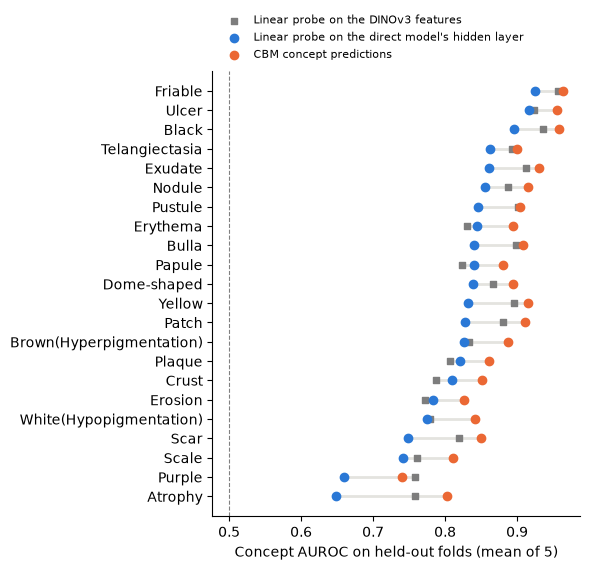

In [8]:
summary = concept_df.groupby(["target", "concept"])[["probe", "probe_dino", "cbm"]].mean()
for target in TARGETS:
    s = summary.loc[target]
    print(f"{target}: probe mean {s.probe.mean():.2f} ({s.probe.min():.2f}-{s.probe.max():.2f}), "
          f"DINOv3 probe mean {s.probe_dino.mean():.2f} ({s.probe_dino.min():.2f}-{s.probe_dino.max():.2f}), "
          f"CBM mean {s.cbm.mean():.2f} ({s.cbm.min():.2f}-{s.cbm.max():.2f}), "
          f"CBM > probe on {(s.cbm > s.probe).sum()}/{len(s)} concepts, "
          f"DINOv3 probe > hidden-layer probe on {(s.probe_dino > s.probe).sum()}/{len(s)}")

# Figure 2 (9-partition models), concepts sorted by probe AUROC.
s = summary.loc["nine_partition_label"].sort_values("probe")
fig, ax = plt.subplots(figsize=(6, 5.8))
yy = np.arange(len(s))
ax.hlines(yy, s.min(axis=1), s.max(axis=1), color="#e4e3df", linewidth=2)
ax.scatter(s.probe_dino, yy, color=COLORS["dino"], marker="s", s=22, label="Linear probe on the DINOv3 features", zorder=3)
ax.scatter(s.probe, yy, color=COLORS["direct"], label="Linear probe on the direct model's hidden layer", zorder=3)
ax.scatter(s.cbm, yy, color=COLORS["cbm"], label="CBM concept predictions", zorder=3)
ax.axvline(0.5, color="grey", linestyle="--", linewidth=0.8)
ax.set(yticks=yy, yticklabels=s.index, xlabel="Concept AUROC on held-out folds (mean of 5)")
ax.legend(frameon=False, fontsize=8, loc="lower left", bbox_to_anchor=(0, 1))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

## 7. Grad-CAM setup (fold 0, 9-partition)

To get image heatmaps, we stack the fold-0 models on top of the **live** DINOv3 backbone.
Grad-CAM explains a scalar output $s$ (a class score or a concept score) through the patch tokens $T_{pd}$ at the input of block 21:

$$L_p = \mathrm{ReLU}\Big(\sum_d \alpha_d T_{pd}\Big), \qquad \alpha_d = \frac{1}{P}\sum_p \frac{\partial s}{\partial T_{pd}}$$

This gives a $16 \times 16$ map, scaled to $[0, 1]$. First we check that the live backbone reproduces the stored CLS features, since the models were trained on those.

In [9]:
class GradCam:
    # DINOv3 with a hook on block 21: everything before the hook runs without a graph, so backward is cheap.

    def __init__(self, block=GRADCAM_BLOCK):
        self.model, self.transform = load_dinov3()
        self.view = type(self.transform)(self.transform.transforms[:-2])   # resize + crop only, for overlays
        self.n_prefix = self.model.num_prefix_tokens                       # CLS + register tokens
        self.model.blocks[block].norm1.register_forward_hook(self._hook)

    def _hook(self, module, inputs, output):
        self.tokens = output.detach().requires_grad_(True)
        return self.tokens

    def cls(self, image):
        with torch.enable_grad():
            return self.model.forward_features(self.transform(image)[None].to(DEVICE))[:, 0]

    def maps(self, scalars):
        # One map per scalar output; all share the same forward pass.
        patches = self.tokens[0, self.n_prefix:]
        side = int(len(patches) ** 0.5)
        out = []
        for s in scalars:
            grad, = torch.autograd.grad(s, self.tokens, retain_graph=True)
            cam = F.relu(patches.detach() @ grad[0, self.n_prefix:].mean(0)).reshape(side, side)
            out.append((cam / cam.max() if cam.max() > 0 else cam).cpu().numpy())
        return out


d = data["nine_partition_label"]
classes, names = d["classes"], d["concept_names"]
direct, cbm = fold0["direct"], fold0["cbm"]
for p in [*direct.parameters(), *cbm.parameters()]:
    p.requires_grad_(False)
mu, s = (torch.from_numpy(a).to(DEVICE) for a in (fold0["mu"], fold0["s"]))
te = fold0["te"]

image_paths = index_images(pd.read_csv(METADATA_FILE))
gradcam = GradCam()

cosines = [F.cosine_similarity(gradcam.cls(load_image(image_paths[d["md5hash"][i]]))[0].float().cpu(),
                               torch.from_numpy(d["X"][i]), dim=0).item() for i in te[:20]]
print(f"live vs stored CLS, 20 images: min cosine = {min(cosines):.5f}")
assert min(cosines) > 0.99

live vs stored CLS, 20 images: min cosine = 1.00000


### SHAP: which concepts drove the CBM's decision?

The CBM's class score is linear in its concepts, $\mathrm{logit}_k = \sum_j A_{kj}\hat c_j + a_k$.
We use the average training image as the baseline, with concept probabilities $\bar c_j$. The exact SHAP value of concept $j$ for class $k$ is then

$$\varphi_{kj}(x) = A_{kj}\,\big(\hat c_j(x) - \bar c_j\big),$$

and the $\varphi_{kj}$ of all 22 concepts sum to $\mathrm{logit}_k(x) - \mathrm{logit}_k(\text{average image})$.

**Figure 4.** For three diagnoses, the average SHAP value of every concept towards that diagnosis, over the test images of all 5 folds that the CBM classifies correctly as that diagnosis (computed in the cross-validation loop of section 5).

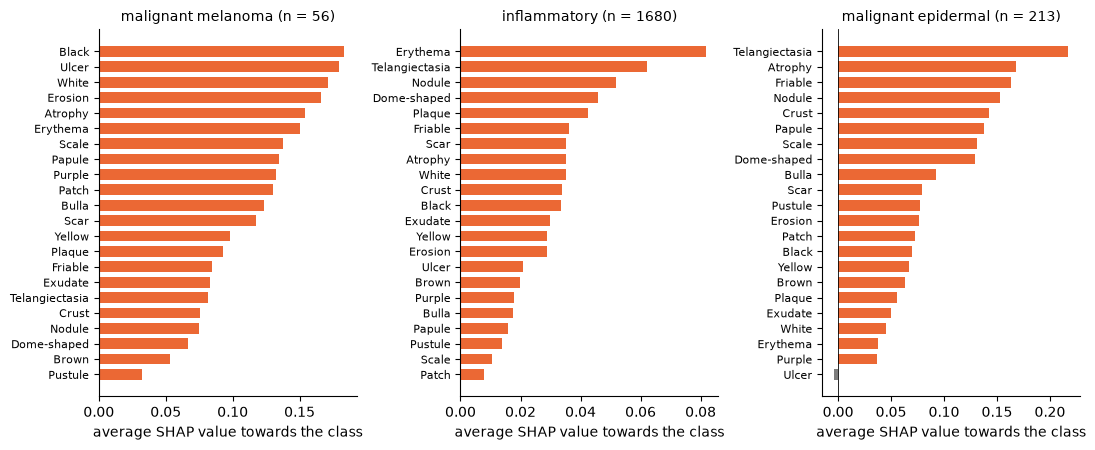

In [10]:
SHAP_CLASSES = ["malignant melanoma", "inflammatory", "malignant epidermal"]
d = data["nine_partition_label"]
short = lambda name: name.replace("(Hyperpigmentation)", "").replace("(Hypopigmentation)", "").strip()

fig, axes = plt.subplots(1, 3, figsize=(11, 4.6))
for ax, cls in zip(axes, SHAP_CLASSES):
    k = d["classes"].index(cls)
    rows = shap_df[(shap_df.pred == k) & (shap_df.true == k)][d["concept_names"]]
    mean = rows.mean().sort_values()
    yy = np.arange(len(mean))
    ax.barh(yy, mean, color=np.where(mean > 0, COLORS["cbm"], COLORS["dino"]), height=0.7)
    ax.axvline(0, color="k", linewidth=0.6)
    ax.set(yticks=yy, yticklabels=[short(c) for c in mean.index], xlabel="average SHAP value towards the class")
    ax.set_title(f"{cls} (n = {len(rows)})", fontsize=10)
    ax.tick_params(axis="y", labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

### Per-image analysis

For each test image we compute:
* the direct model's map for its predicted class;
* the CBM's map for every concept **annotated** as present (used for Q2, section 9);
* the CBM's **focus region** (Q1). Among the concepts that are both annotated and predicted present ($\hat c_j > 0.5$), we take the two with the highest SHAP value towards the CBM's predicted class. The focus region is the union of their top-20% patches.

Maps with no positive evidence carry no location and are left out of the metrics.

In [11]:
with torch.no_grad():   # SHAP baseline: mean concept probability over the fold-0 training images
    c_bar = torch.sigmoid(cbm.concept_part((torch.from_numpy(d["X"][fold0["tr"]]).to(DEVICE) - mu) / s)).mean(0)
A = cbm.classifier.weight


def is_flat(cam):
    return cam.max() == cam.min()


def top_mask(cam):
    # The 20% highest patches (51 of 256), counting only patches with a positive score.
    k = int(round(TOP_FRACTION * cam.size))
    mask = np.zeros(cam.size, bool)
    mask[np.argsort(-cam.ravel(), kind="stable")[:k]] = True
    return (mask & (cam.ravel() > 0)).reshape(cam.shape)


def union(cams):
    usable = [c for c in cams if not is_flat(c)]
    return np.logical_or.reduce([top_mask(c) for c in usable]) if usable else None


def analyse(i):
    # All maps and metrics for one test image (i indexes the 9-partition data).
    image = load_image(image_paths[d["md5hash"][i]])
    z = (gradcam.cls(image) - mu) / s
    d_logits = direct(z)
    c_logits, k_logits = cbm(z)
    d_pred, k_pred = int(d_logits.argmax()), int(k_logits.argmax())
    probs = torch.sigmoid(c_logits[0])
    annotated = np.flatnonzero(d["C"][i] > 0)

    maps = gradcam.maps([d_logits[0, d_pred]] + [c_logits[0, j] for j in annotated])
    d_cam, concept_cam = maps[0], dict(zip(annotated, maps[1:]))

    # Q1: the CBM's focus region = the two annotated & predicted concepts with the highest SHAP value.
    shap = (A[k_pred] * (probs - c_bar)).detach().cpu().numpy()
    both = [j for j in annotated if probs[j] > 0.5]
    top = sorted(both, key=lambda j: -shap[j])[:2]
    focus = union([concept_cam[j] for j in top])
    iou = np.nan
    if focus is not None and not is_flat(d_cam):
        iou = (top_mask(d_cam) & focus).sum() / (top_mask(d_cam) | focus).sum()

    # Q2: share of the direct model's top patches outside the region of all annotated concepts.
    region = union(concept_cam.values())
    outside = outside_chance = np.nan
    if region is not None and not is_flat(d_cam):
        outside = (top_mask(d_cam) & ~region).sum() / top_mask(d_cam).sum()
        outside_chance = 1 - region.mean()      # what randomly placed patches would give

    return {"md5hash": d["md5hash"][i], "true": classes[d["y"][i]], "direct_pred": classes[d_pred],
            "cbm_pred": classes[k_pred], "image": gradcam.view(image), "direct_cam": d_cam,
            "top": [(names[j], probs[j].item(), shap[j], concept_cam[j]) for j in top], "iou": iou,
            "annotated": [(names[j], concept_cam[j]) for j in annotated],
            "outside": outside, "outside_chance": outside_chance}


# 200 random test images with at least one annotated concept.
rng = np.random.default_rng(SEED)
chosen = rng.permutation(te[d["C"][te].sum(1) > 0])[:N_GRADCAM_IMAGES]
records = [analyse(i) for i in chosen]
print(f"analysed {len(records)} images")

analysed 200 images


### One image explained through its concepts (Figure 3)

Candidates: fold-0 test images that the CBM classifies correctly, with at least two concepts that are both annotated and predicted present, and whose concept with the highest SHAP value is one of them. The figure shows one of them, chosen by eye.
From left to right: the image; the concepts the CBM predicts as present ($\hat c_j > 0.5$, ✓ = also annotated by the dermatologist); how the SHAP values of the concepts move the class score from the average image to this image (the five largest, then the rest together); and the Grad-CAM map of the concept with the highest SHAP value.

235 candidates: {'inflammatory': 220, 'malignant epidermal': 6, 'genodermatoses': 3, 'benign epidermal': 3, 'benign dermal': 2, 'malignant melanoma': 1}


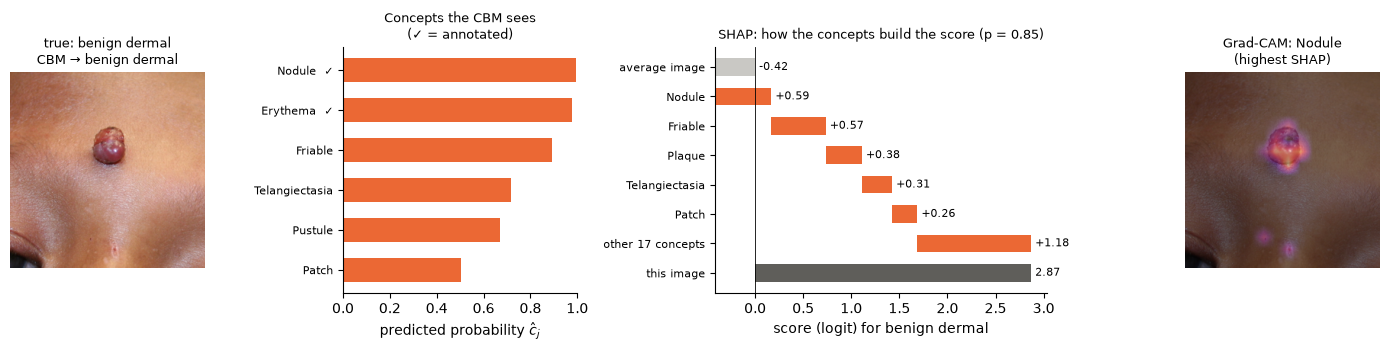

In [12]:
WORKED_EXAMPLE = "b935d5f370685fbfdfb676b492dd5deb"   # md5hash of the image chosen by eye among the candidates


def show_map(ax, image, cam=None, title=""):
    ax.imshow(image)
    if cam is not None:
        up = np.array(Image.fromarray((cam * 255).astype(np.uint8)).resize(image.size, Image.BILINEAR)) / 255
        ax.imshow(up, cmap="magma", alpha=0.5, vmin=0, vmax=1)
    ax.set_title(title, fontsize=9)
    ax.axis("off")


def explain(i):
    # Concept probabilities, SHAP values towards the predicted class, and the map of the top-SHAP concept.
    image = load_image(image_paths[d["md5hash"][i]])
    z = (gradcam.cls(image) - mu) / s
    c_logits, k_logits = cbm(z)
    k = int(k_logits.argmax())
    probs = torch.sigmoid(c_logits[0])
    shap = (A[k] * (probs - c_bar)).detach().cpu().numpy()
    top = int(np.argmax(shap))
    cam, = gradcam.maps([c_logits[0, top]])
    return {"i": i, "md5hash": d["md5hash"][i], "image": gradcam.view(image), "k": k,
            "p": torch.softmax(k_logits[0], 0)[k].item(), "logit": k_logits[0, k].item(),
            "base": (A[k] @ c_bar + cbm.classifier.bias[k]).item(),        # class score of the average image
            "probs": probs.detach().cpu().numpy(), "shap": shap, "top": top, "cam": cam,
            "annotated": d["C"][i] > 0}


candidates = []
for i in te:
    e = explain(i)
    both = e["annotated"] & (e["probs"] > 0.5)
    if e["k"] == d["y"][i] and both.sum() >= 2 and both[e["top"]]:
        candidates.append(e)
print(f"{len(candidates)} candidates:", pd.Series([classes[e["k"]] for e in candidates]).value_counts().to_dict())
ex = next(e for e in candidates if e["md5hash"] == WORKED_EXAMPLE) if WORKED_EXAMPLE else candidates[0]

fig, ax = plt.subplots(1, 4, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1, 1.2, 1.7, 1]})
show_map(ax[0], ex["image"], title=f"true: {classes[d['y'][ex['i']]]}\nCBM → {classes[ex['k']]}")

present = np.flatnonzero(ex["probs"] > 0.5)
present = present[np.argsort(ex["probs"][present])]
ax[1].barh(np.arange(len(present)), ex["probs"][present], color=COLORS["cbm"], height=0.6)
ax[1].set(yticks=np.arange(len(present)), xlim=(0, 1), xlabel="predicted probability $\\hat c_j$",
          yticklabels=[short(names[j]) + ("  ✓" if ex["annotated"][j] else "") for j in present])
ax[1].set_title("Concepts the CBM sees\n(✓ = annotated)", fontsize=9)

N_SHOWN = 5
order = np.argsort(-np.abs(ex["shap"]))[:N_SHOWN]
steps = [(short(names[j]), ex["shap"][j]) for j in order]
steps.append((f"other {len(names) - N_SHOWN} concepts", ex["shap"].sum() - ex["shap"][order].sum()))
x = ex["base"]
ax[2].barh(0, ex["base"], color="#c9c8c4", height=0.6)
ax[2].text(max(ex["base"], 0), 0, f" {ex['base']:.2f}", va="center", ha="left", fontsize=8)   # right of the bar or of 0
for row, (label, v) in enumerate(steps, start=1):
    ax[2].barh(row, v, left=x, color=COLORS["cbm"] if v > 0 else COLORS["dino"], height=0.6)
    ax[2].text(x + v, row, f" {v:+.2f}" if v > 0 else f"{v:+.2f} ", va="center", ha="left" if v > 0 else "right", fontsize=8)
    x += v
ax[2].barh(len(steps) + 1, ex["logit"], color="#5f5e5a", height=0.6)
ax[2].text(ex["logit"], len(steps) + 1, f" {ex['logit']:.2f}", va="center", ha="left" if ex["logit"] >= 0 else "right", fontsize=8)
ax[2].axvline(0, color="k", linewidth=0.6)
ax[2].set(yticks=np.arange(len(steps) + 2), yticklabels=["average image"] + [l for l, _ in steps] + ["this image"],
          xlabel=f"score (logit) for {classes[ex['k']]}")
ax[2].invert_yaxis()
ax[2].set_title(f"SHAP: how the concepts build the score (p = {ex['p']:.2f})", fontsize=9)
for a in ax[1:3]:
    a.spines[["top", "right"]].set_visible(False)
    a.tick_params(axis="y", labelsize=8)

show_map(ax[3], ex["image"], ex["cam"], f"Grad-CAM: {short(names[ex['top']])}\n(highest SHAP)")
fig.tight_layout()

### Why block 21: the CBM's "Erythema" map at the last block and at block 21 (Figure 5)

The same Grad-CAM computation, once on the tokens at the input of the last block (24) and once at block 21, for the CBM's score of the concept "Erythema" (redness) on one test image annotated with it (chosen by eye).

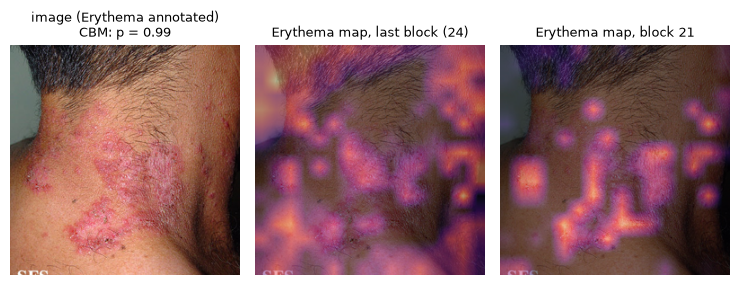

In [13]:
BLOCK_EXAMPLE = "f224e592fe598770e63d832b5d5df2fb"   # md5hash of the image chosen by eye

last_block = GradCam(block=-1)
erythema = names.index("Erythema")
index_of_md5 = {m: i for i, m in enumerate(d["md5hash"])}


def concept_map(cam_model, image, j):
    z = (cam_model.cls(image) - mu) / s
    c_logits, _ = cbm(z)
    return cam_model.maps([c_logits[0, j]])[0], torch.sigmoid(c_logits[0, j]).item()


i = index_of_md5[BLOCK_EXAMPLE] if BLOCK_EXAMPLE else next(i for i in te if d["C"][i, erythema] > 0)
image = load_image(image_paths[d["md5hash"][i]])
cam_last, p = concept_map(last_block, image, erythema)
cam_21, _ = concept_map(gradcam, image, erythema)

fig, ax = plt.subplots(1, 3, figsize=(7.5, 2.8))
view = gradcam.view(image)
show_map(ax[0], view, title=f"image (Erythema annotated)\nCBM: p = {p:.2f}")
show_map(ax[1], view, cam_last, "Erythema map, last block (24)")
show_map(ax[2], view, cam_21, "Erythema map, block 21")
fig.tight_layout()

del last_block
torch.cuda.empty_cache()

## 8. Q1: where do the two models look? (Figure 6)

We only consider images where both models predict the same, correct class, all shown concepts have a positive SHAP value, and every map has a full-size top-20% region.
**Left:** the images with the highest overlap (IoU) between the direct model's top-20% patches and the CBM's focus region, at most two per class.
**Right:** four images chosen by eye from the fold-0 test images with an overlap of at most 0.10.

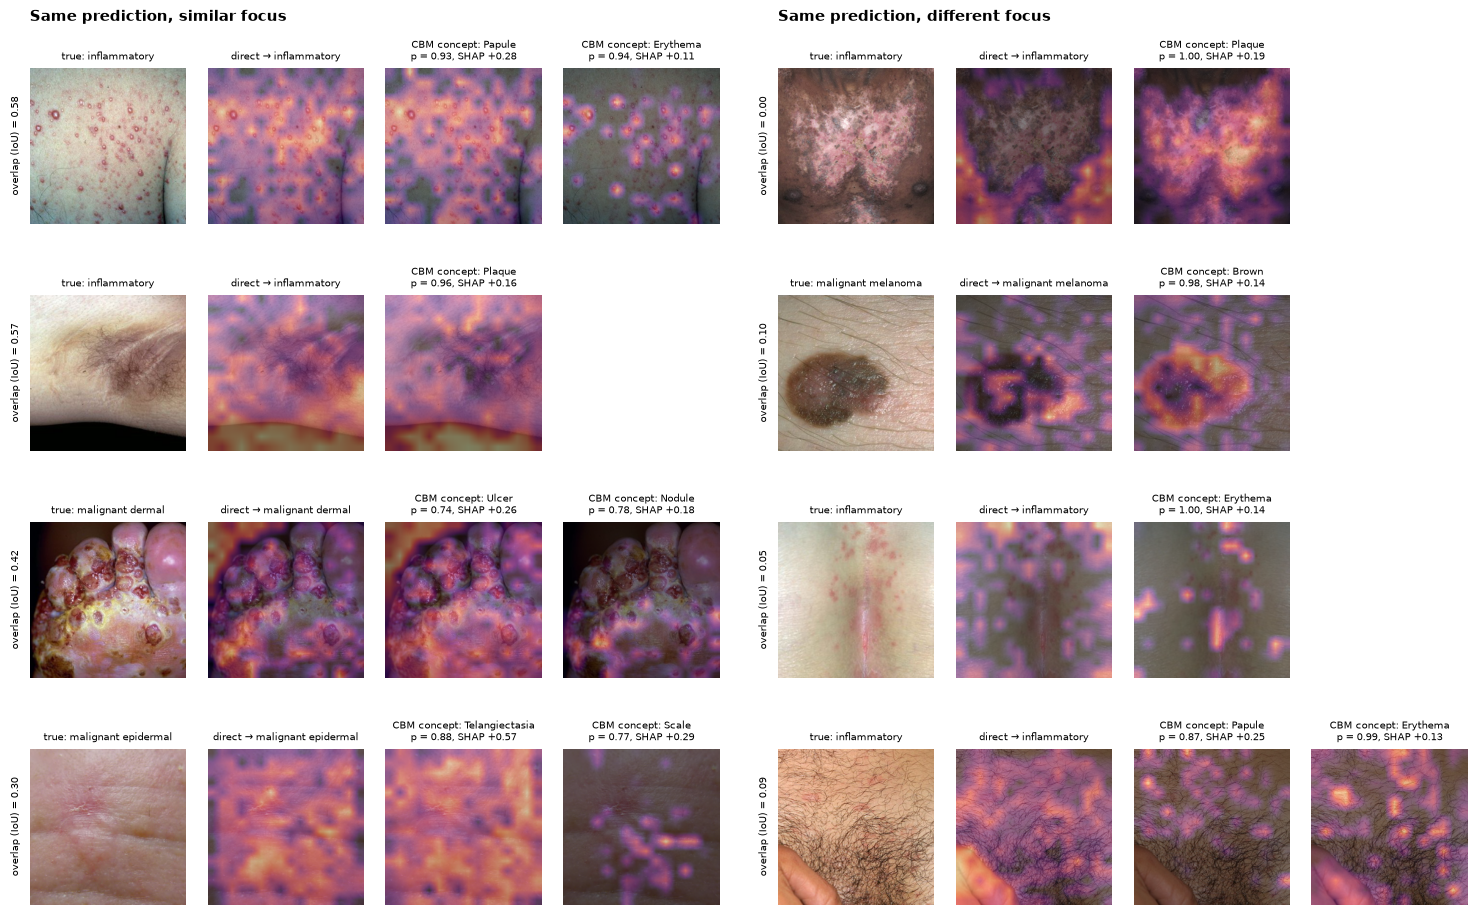

In [14]:
FULL = int(round(TOP_FRACTION * 256))
DIFFERENT_FOCUS = ["34aa648c5d13cc995c0f0892c90e7de0", "b373d991b75e405e4d1d3b2bf805a5df",
                   "64f7e067036811860d60594b1d935077", "57ed644fa03512a8c2fcf27c9de6b9cb"]


def eligible(r):
    return (r["direct_pred"] == r["cbm_pred"] == r["true"] and r["top"] and min(t[2] for t in r["top"]) > 0
            and top_mask(r["direct_cam"]).sum() == FULL and all(top_mask(t[3]).sum() == FULL for t in r["top"]))


def pick_varied(recs, n=4, per_class=2):
    picked, count = [], {}
    for r in recs:
        if count.get(r["direct_pred"], 0) < per_class:
            picked.append(r)
            count[r["direct_pred"]] = count.get(r["direct_pred"], 0) + 1
        if len(picked) == n:
            break
    return picked


def overlay(ax, r, cam=None, title=""):
    ax.imshow(r["image"])
    if cam is not None:
        up = np.array(Image.fromarray((cam * 255).astype(np.uint8)).resize(r["image"].size, Image.BILINEAR)) / 255
        ax.imshow(up, cmap="magma", alpha=0.5, vmin=0, vmax=1)
    ax.set_title(title, fontsize=7)
    ax.axis("off")


ranked = sorted([r for r in records if not np.isnan(r["iou"]) and eligible(r)], key=lambda r: -r["iou"])
by_md5 = {r["md5hash"]: r for r in records}
index_of = {m: i for i, m in enumerate(d["md5hash"])}
sides = [("Same prediction, similar focus", pick_varied(ranked)),
         ("Same prediction, different focus",
          [by_md5.get(m) or analyse(index_of[m]) for m in DIFFERENT_FOCUS])]

short = lambda name: name.replace("(Hyperpigmentation)", "").replace("(Hypopigmentation)", "")
fig, axes = plt.subplots(4, 9, figsize=(15, 9.2), gridspec_kw={"width_ratios": [1] * 4 + [0.15] + [1] * 4,
                                                               "wspace": 0.08, "hspace": 0.45,
                                                               "left": 0.03, "right": 0.995, "top": 0.92, "bottom": 0.01})
for g, (heading, recs) in enumerate(sides):
    for row, r in enumerate(recs):
        ax = axes[row, 5 * g: 5 * g + 4]
        overlay(ax[0], r, title=f"true: {r['true']}")
        ax[0].text(-0.06, 0.5, f"overlap (IoU) = {r['iou']:.2f}", transform=ax[0].transAxes, rotation=90, va="center", ha="right", fontsize=7)
        overlay(ax[1], r, r["direct_cam"], f"direct → {r['direct_pred']}")
        for k in range(2):
            if k < len(r["top"]):
                name, p, phi, cam = r["top"][k]
                overlay(ax[2 + k], r, cam, f"CBM concept: {short(name)}\np = {p:.2f}, SHAP {phi:+.2f}")
            else:
                ax[2 + k].axis("off")
    axes[0, 5 * g].annotate(heading, (0, 1.3), xycoords="axes fraction", fontsize=11, fontweight="bold")
for ax in axes[:, 4]:
    ax.axis("off")

## 9. Q2: does the direct model use features beyond the concepts? (Figure 7)

The **concept region** is the union of the top-20% patches of the CBM's maps for all annotated concepts.
The **outside share** $O$ is the fraction of the direct model's top-20% patches that fall outside this region.

In [15]:
q2 = pd.DataFrame([{k: r[k] for k in ["outside", "outside_chance"]} for r in records]).dropna()
print(f"{len(q2)} images: mean outside share {q2.outside.mean():.0%} (random patches: {q2.outside_chance.mean():.0%})")

185 images: mean outside share 51% (random patches: 62%)


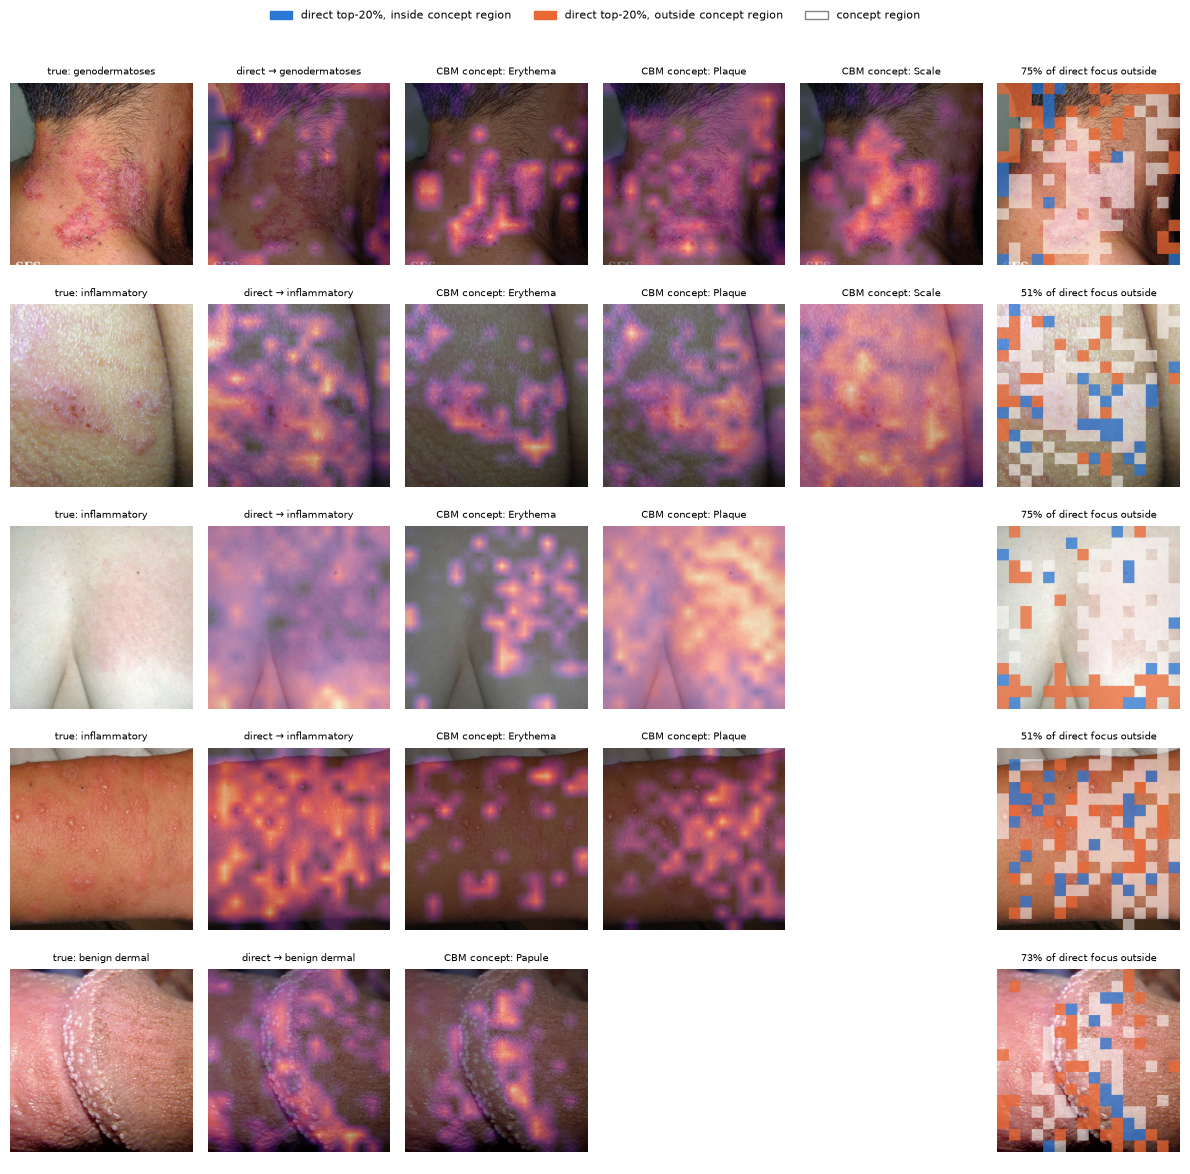

In [16]:
# Figure 7: correctly classified images chosen by eye (outside share >= 50%, concept maps clearly on the lesions).
Q2_EXAMPLES = ["f224e592fe598770e63d832b5d5df2fb", "6a7fc9ebe9f13fcd62f92d253e3d52a9", "6c2bb59f2beeaea6fd2807a6f7ea60a4",
               "cc721a1eb83c779afae519d27b7848e6", "c947a671109f3d95e08eca2e1c42d526"]
examples = [by_md5.get(m) or analyse(index_of[m]) for m in Q2_EXAMPLES]
INSIDE, OUTSIDE = "#2a78d6", "#eb6834"

n_cols = 3 + max(len(r["annotated"]) for r in examples)
fig, axes = plt.subplots(len(examples), n_cols, figsize=(2 * n_cols, 2.25 * len(examples) + 0.5))
for ax, r in zip(axes, examples):
    overlay(ax[0], r, title=f"true: {r['true']}")
    overlay(ax[1], r, r["direct_cam"], f"direct → {r['direct_pred']}")
    for k in range(n_cols - 3):
        if k < len(r["annotated"]):
            overlay(ax[2 + k], r, r["annotated"][k][1], f"CBM concept: {r['annotated'][k][0]}")
        else:
            ax[2 + k].axis("off")
    # Last column: concept region (white), direct top patches inside (blue) / outside (orange).
    region, top = union([c for _, c in r["annotated"]]), top_mask(r["direct_cam"])
    big = lambda m: np.array(Image.fromarray(m.astype(np.uint8) * 255).resize(r["image"].size, Image.NEAREST)) > 0
    rgba = np.zeros((*r["image"].size[::-1], 4))
    rgba[big(region)] = (1, 1, 1, 0.55)
    rgba[big(top & region)] = (*to_rgb(INSIDE), 0.75)
    rgba[big(top & ~region)] = (*to_rgb(OUTSIDE), 0.75)
    overlay(ax[-1], r, title=f"{r['outside']:.0%} of direct focus outside")
    ax[-1].imshow(rgba)
fig.legend(handles=[mpatches.Patch(color=INSIDE, label="direct top-20%, inside concept region"),
                    mpatches.Patch(color=OUTSIDE, label="direct top-20%, outside concept region"),
                    mpatches.Patch(facecolor="white", edgecolor="grey", label="concept region")],
           loc="upper center", ncol=3, fontsize=8, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.96))